In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.linear_model import LinearRegression

In [6]:
df = pd.read_csv('Nat_Gas.csv')

In [9]:
df['Dates'] = pd.to_datetime(df['Dates'])
df['Price'] = pd.to_numeric(df['Prices'])
print(df.head())

       Dates  Prices  Price
0 2020-10-31    10.1   10.1
1 2020-11-30    10.3   10.3
2 2020-12-31    11.0   11.0
3 2021-01-31    10.9   10.9
4 2021-02-28    10.9   10.9


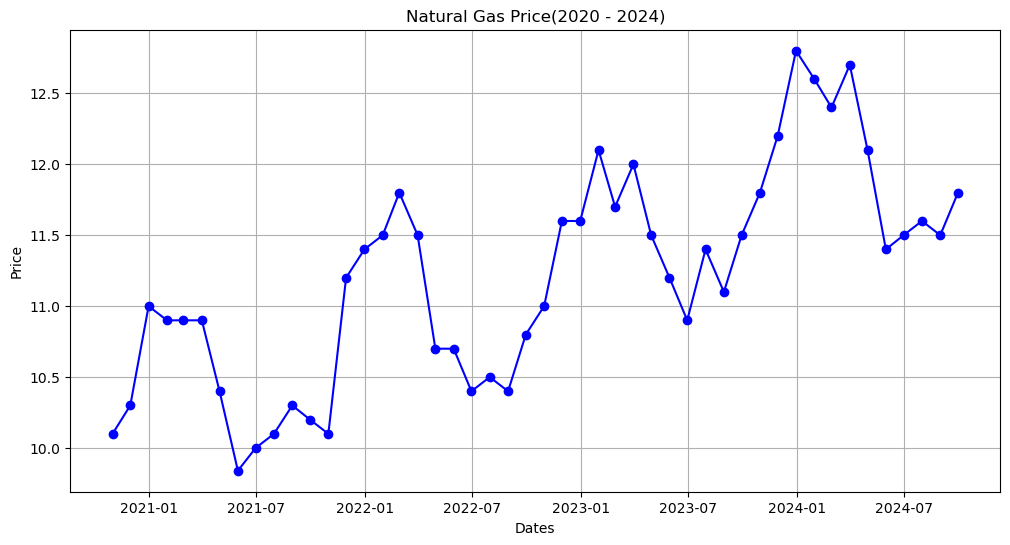

In [11]:
plt.figure(figsize=(12,6))
plt.plot(df['Dates'], df['Price'], marker='o', color='b', linestyle='solid')
plt.title('Natural Gas Price(2020 - 2024)')
plt.xlabel('Dates')
plt.ylabel('Price')
plt.grid(True)
plt.show()
           

In [15]:
df['Date_Ordinal']= df['Dates'].map(datetime.toordinal)
X=df[['Date_Ordinal']]
y=df['Price']
model= LinearRegression()
model.fit(X,y)
print("---Model Training Successful!---")
print("Trend line Slope (m):", model.coef_[0])
print("Trend Line Intercept (c):", model.intercept_)



---Model Training Successful!---
Trend line Slope (m): 0.0012823735987602212
Trend Line Intercept (c): -935.753151513827


In [29]:
def get_gas_price(input_date_str):
    try:
        input_date = pd.to_datetime(input_date_str)
        input_ordinal = input_date.toordinal()
        min_date = df['Dates'].min()
        max_date = df['Dates'].max()
        
        # Yahan if block try ke andar perfectly indented hai
        if min_date <= input_date <= max_date:
            estimated_price = np.interp(input_ordinal, df['Date_Ordinal'], df['Prices'])
            print(f"[{input_date_str}](Interpolation).")
            
        else:
            estimated_price = model.predict(pd.DataFrame([[input_ordinal]], columns=['Date_Ordinal']))[0]
            print(f"Date[{input_date_str}](Extrapolation).")
            
        return round(estimated_price, 2)
        
    except Exception as e:
        return f"Error: Date format is wrong. Details: {e}"

In [30]:
print(" Testing JP MORGAN TESK CODE \n")
past_test_date = '2022-05-15'
past_price= get_gas_price(past_test_date)
print(f"Calculated Price:${past_price}\n")

future_test_date = '2025-06-20'
future_price = get_gas_price(future_test_date)
print(f"Prediction Price: ${future_price}\n")
print("-------------------------------")
      

 Testing JP MORGAN TESK CODE 

[2022-05-15](Interpolation).
Calculated Price:$10.7

Date[2025-06-20](Extrapolation).
Prediction Price: $12.46

-------------------------------
